# Лабораторная работа №1. Описательная статистика и первые гипотезы

## Контекст задачи

Вы — аналитик данных в страховой компании **MedGuard**, которая продаёт полисы добровольного медицинского страхования (ДМС) в четырёх регионах США.

Продакт-менеджер (PM) готовит пересмотр тарифов и маркетинговой стратегии на следующий год. Перед тем как обсуждать что-либо с финансовым отделом, ему нужен **фактический портрет клиентской базы** и проверка нескольких утверждений, которые сейчас в компании принимаются «на веру».

Из внутренней переписки PM:

> «У нас есть выгрузка по 1 338 застрахованным за прошлый год. Мне нужно понять, кто наши клиенты, сколько мы на них реально тратим, и правда ли то, что говорят маркетинг и финансы. Ответы нужны с цифрами, а не с ощущениями. Каждый вывод — с обоснованием, почему ты в нём уверен».

**Ваша задача** — пройти по данным от описательной статистики до проверки гипотез и в конце написать короткий отчёт для PM.

---

## Датасет

Используем открытый датасет **Medical Cost Personal Dataset** (страховые выплаты по клиентам).

**Скачайте файл самостоятельно** по ссылке и положите его в одну папку с этим ноутбуком:

- https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv (правая кнопка → «Сохранить как…» → `insurance.csv`)
- Зеркало на Kaggle: https://www.kaggle.com/datasets/mirichoi0218/insurance

Описание колонок:

| Колонка | Описание |
|---|---|
| `age` | возраст застрахованного, лет |
| `sex` | пол: `male` / `female` |
| `bmi` | индекс массы тела (кг/м²) |
| `children` | количество детей, покрытых полисом |
| `smoker` | курит ли клиент: `yes` / `no` |
| `region` | регион проживания: `northeast`, `northwest`, `southeast`, `southwest` |
| `charges` | сумма страховых выплат за год, USD |

---

## Правила выполнения

1. Все расчёты — в коде (`numpy`, `pandas`, `scipy.stats`, `matplotlib`/`seaborn`), как в лекции.
2. После каждого задания — **вывод СВОИМИ словами** в markdown-ячейке: что посчитали, что это значит для бизнеса.
3. Уровень значимости во всех проверках гипотез: $\alpha = 0.05$.
4. Для проверки гипотез используем **z-критерий для среднего** и доверительные интервалы, как в лекции (выборка большая, $N > 30$, поэтому вместо $\sigma$ ГС берём $sd$ выборки).
5. Ячейки с `# ваш код` — заполняете вы. Ячейки с `**Вывод:**` — тоже вы.

In [1]:
import math
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")
np.random.seed(42)  # чтобы результаты со случайностью воспроизводились

df = pd.read_csv("insurance.csv")
print(df.shape)
df.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Задание 1. Знакомство с данными и типы переменных

PM просит для начала «просто описать, что у нас за таблица». Но прежде чем считать хоть что-то, нужно понять, **с какими типами переменных** мы работаем — от этого зависит, какие меры и графики допустимы.

**1.1.** Выведите общую информацию о таблице: количество строк и столбцов, типы данных, наличие пропусков (`df.info()`, `df.isna().sum()`, `df.describe(include="all")`).

**1.2.** Заполните таблицу ниже: для каждой колонки определите тип переменной по классификации из лекции
(количественная непрерывная / количественная дискретная / номинативная / ранговая) и **обоснуйте в одном предложении**.

**1.3.** Ответьте: для какой из колонок будет **ошибкой** считать среднее значение, даже если pandas это позволит? Почему?

In [2]:
# 1.1 Общая информация о таблице
print("Размер таблицы (строк, столбцов):", df.shape)
print("\nТипы данных:")
df.info()
print("\nПропуски по столбцам:")
print(df.isna().sum())
print("\nВсего пропусков в таблице:", int(df.isna().sum().sum()))
df.describe(include="all")

Размер таблицы (строк, столбцов): (1338, 7)

Типы данных:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Пропуски по столбцам:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Всего пропусков в таблице: 0


,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


**Вывод (заполните таблицу):**

Таблица цела: 1 338 строк × 7 столбцов, пропусков нет, типы данных адекватны содержимому.

| Колонка | Тип переменной | Обоснование |
|---|---|---|
| `age` | количественная дискретная | Возраст в полных годах — целые значения с минимальным шагом 1 год. |
| `sex` | номинативная | Две категории (`male`/`female`) без естественного порядка; допустимы только частоты и доли. |
| `bmi` | количественная непрерывная | Отношение веса к квадрату роста — принимает любые значения на непрерывной шкале. |
| `children` | количественная дискретная | Счётчик детей — целые числа от 0 и выше. |
| `smoker` | номинативная | Бинарный признак `yes`/`no` без порядка между категориями. |
| `region` | номинативная | Четыре региона — названия-ярлыки без ранга и без естественного порядка. |
| `charges` | количественная непрерывная | Денежная сумма выплат — непрерывная шкала (дробные значения). |

**Ответ на 1.3:** Среднее будет ошибкой для любой номинативной колонки — `sex`, `smoker` и особенно `region`. Даже если закодировать регионы числами (0, 1, 2, 3), среднее «1,2» ничего не будет значить: числа здесь — лишь ярлыки категорий, а не количество, и операции сложения над ними бессмысленны.

## Задание 2. Генеральная совокупность и выборка

Финансовый отдел предлагает сэкономить: вместо обработки всей базы делать выводы по **выборке из 100 клиентов**. PM спрашивает, насколько это безопасно и как правильно отобрать этих 100 человек.

В рамках задания считаем, что наша таблица из 1 338 клиентов — это **генеральная совокупность (ГС)**.

**2.1.** Сделайте **простую случайную выборку** из 100 клиентов (`df.sample(n=100, random_state=...)`). Сравните среднее `charges` и долю курильщиков в выборке и в ГС.

**2.2.** Сделайте **стратифицированную выборку** из 100 клиентов, где страты — это `region` (из каждого региона берём пропорционально его доле в ГС; подсказка: `df.groupby("region", group_keys=False).apply(lambda g: g.sample(frac=100/len(df), random_state=...))`). Сравните те же показатели с ГС.

**2.3.** Повторите простую случайную выборку 5 раз с разными `random_state` и посмотрите, как «прыгает» среднее `charges`. Запишите минимальное и максимальное полученное среднее.

**2.4.** Ответьте PM: можно ли принимать решения по одной выборке из 100 клиентов? Какой из двух способов отбора вы бы рекомендовали и почему? Какие ещё страты (кроме региона) имело бы смысл использовать в этой задаче?

In [3]:
# 2.1 Простая случайная выборка из 100 клиентов
sample_simple = df.sample(n=100, random_state=42)

mu_gs = df.charges.mean()
smoke_gs = (df.smoker == "yes").mean()

print("ГС:               mean charges = %.2f | доля курильщиков = %.3f" % (mu_gs, smoke_gs))
print("Простая выборка:  mean charges = %.2f | доля курильщиков = %.3f" % (
    sample_simple.charges.mean(), (sample_simple.smoker == "yes").mean()))
print("Отклонение среднего выборки от ГС: %+.2f USD (%+.1f%%)" % (
    sample_simple.charges.mean() - mu_gs, 100 * (sample_simple.charges.mean() / mu_gs - 1)))

ГС:               mean charges = 13270.42 | доля курильщиков = 0.205
Простая выборка:  mean charges = 13807.15 | доля курильщиков = 0.220
Отклонение среднего выборки от ГС: +536.73 USD (+4.0%)


In [4]:
# 2.2 Стратифицированная выборка: страты = region, пропорционально доле региона в ГС
# (в pandas 3 groupby.apply исключает группирующий столбец, поэтому собираем выборку через concat)
sample_strat = pd.concat(
    [g.sample(frac=100 / len(df), random_state=42) for _, g in df.groupby("region")]
).sample(frac=1, random_state=42)  # перемешиваем строки

print("Размер стратифицированной выборки:", len(sample_strat), "(получилось 99 из-за округления долей)")
print("Клиентов по регионам в выборке:", sample_strat.region.value_counts().to_dict())
print("Клиентов по регионам в ГС:     ", df.region.value_counts().to_dict())
print()
print("ГС:                  mean charges = %.2f | доля курильщиков = %.3f" % (df.charges.mean(), (df.smoker == "yes").mean()))
print("Стратифицированная:  mean charges = %.2f | доля курильщиков = %.3f" % (
    sample_strat.charges.mean(), (sample_strat.smoker == "yes").mean()))
print("Отклонение среднего от ГС: %+.2f USD (%+.1f%%)" % (
    sample_strat.charges.mean() - df.charges.mean(), 100 * (sample_strat.charges.mean() / df.charges.mean() - 1)))

Размер стратифицированной выборки: 99 (получилось 99 из-за округления долей)
Клиентов по регионам в выборке: {'southeast': 27, 'northwest': 24, 'southwest': 24, 'northeast': 24}
Клиентов по регионам в ГС:      {'southeast': 364, 'southwest': 325, 'northwest': 325, 'northeast': 324}

ГС:                  mean charges = 13270.42 | доля курильщиков = 0.205
Стратифицированная:  mean charges = 12130.29 | доля курильщиков = 0.202
Отклонение среднего от ГС: -1140.14 USD (-8.6%)


In [5]:
# 2.3 Пять повторов простой случайной выборки
sample_means = {}
for rs in [1, 2, 3, 4, 5]:
    m = df.sample(n=100, random_state=rs).charges.mean()
    sample_means[rs] = m
    print("random_state=%d: среднее charges = %8.2f (отклонение от ГС: %+7.2f)" % (rs, m, m - df.charges.mean()))

print()
print("Минимальное среднее:  %.2f" % min(sample_means.values()))
print("Максимальное среднее: %.2f" % max(sample_means.values()))
print("Разброс max - min:    %.2f USD (≈ %.0f%% от среднего ГС)" % (
    max(sample_means.values()) - min(sample_means.values()),
    100 * (max(sample_means.values()) - min(sample_means.values())) / df.charges.mean()))

random_state=1: среднее charges = 14859.44 (отклонение от ГС: +1589.02)
random_state=2: среднее charges = 12067.29 (отклонение от ГС: -1203.13)
random_state=3: среднее charges = 12531.14 (отклонение от ГС: -739.28)
random_state=4: среднее charges = 12837.91 (отклонение от ГС: -432.51)
random_state=5: среднее charges = 11930.06 (отклонение от ГС: -1340.36)

Минимальное среднее:  11930.06
Максимальное среднее: 14859.44
Разброс max - min:    2929.38 USD (≈ 22% от среднего ГС)


**Вывод:**

- Простая случайная выборка (n=100): среднее `charges` = 13 807 USD против 13 270 в ГС (+4,0%), доля курильщиков 22,0% против 20,5%. Оценки близки к истине, но не совпадают с ней точно.
- Стратифицированная выборка по региону (получилось 99 человек из-за округления долей): состав по регионам пропорционален ГС, доля курильщиков 20,2% почти точна, но среднее `charges` = 12 130 USD (−8,6% от ГС) — попало даже дальше, чем простая выборка: стратификация по региону не контролирует главный драйвер выплат, курение.
- 5 повторов простой выборки: среднее «прыгает» от 11 930 до 14 859 USD, разброс ≈ 2 929 USD — около ±11% от среднего ГС.

**Ответ PM:** по одной выборке из 100 человек решения принимать нельзя — оценка нестабильна от случая к случаю (п. 2.3), и «портрет клиента» может съехать на тысячи долларов. Из двух способов я рекомендую **стратифицированный**, но со стратой `smoker` в первую очередь: он гарантирует, что редкие, но дорогие подгруппы попадут в выборку в верной пропорции (регион сам по себе почти не влияет на выплаты, что видно из задания 5). Ещё разумные страты: `age` (например, 18–29 / 30–49 / 50+) и `children` (есть дети / нет). А надёжнее всего — смотреть не на точечную оценку, а на доверительный интервал (задание 8): он честно показывает, насколько далеко может лежать истина.

## Задание 3. Портрет клиента: меры центральной тенденции

PM хочет одну цифру на слайд: «средний клиент MedGuard — это …».

**3.1.** Для переменных `age`, `bmi`, `charges` посчитайте **моду, медиану и среднее** (`stats.mode`, `np.median`, `np.mean` или методы pandas). Соберите результат в одну таблицу.

**3.2.** Постройте гистограммы этих трёх переменных (по одной на каждую, `bins=30`). На каждой гистограмме вертикальными линиями отметьте среднее и медиану.

**3.3.** Для каждой переменной ответьте: распределение симметричное или скошенное? Есть ли заметные выбросы / несколько мод? Какую меру центральной тенденции вы **порекомендуете PM для слайда** и почему (опирайтесь на раздел «Примеры использования» из лекции)?

**3.4.** Проверьте свойство среднего: PM хочет показать выплаты **в тысячах долларов**. Создайте колонку `charges_k = charges / 1000` и покажите, что среднее изменилось ровно в 1000 раз, **не пересчитывая среднее заново по данным** — только через свойство $M_{x \cdot c} = c \cdot M_x$.

In [6]:
# 3.1 Мода, медиана и среднее для age, bmi, charges — одна таблица
rows = []
for col in ["age", "bmi", "charges"]:
    mode_res = stats.mode(df[col], keepdims=True)
    rows.append({
        "переменная": col,
        "мода": mode_res.mode[0],
        "частота моды": int(mode_res.count[0]),
        "медиана": round(df[col].median(), 2),
        "среднее": round(df[col].mean(), 2),
    })
central = pd.DataFrame(rows)
central

,переменная,мода,частота моды,медиана,среднее
0,age,18.0000,69,39.00,39.21
1,bmi,32.3000,13,30.40,30.66
2,charges,1639.5631,2,9382.03,13270.42


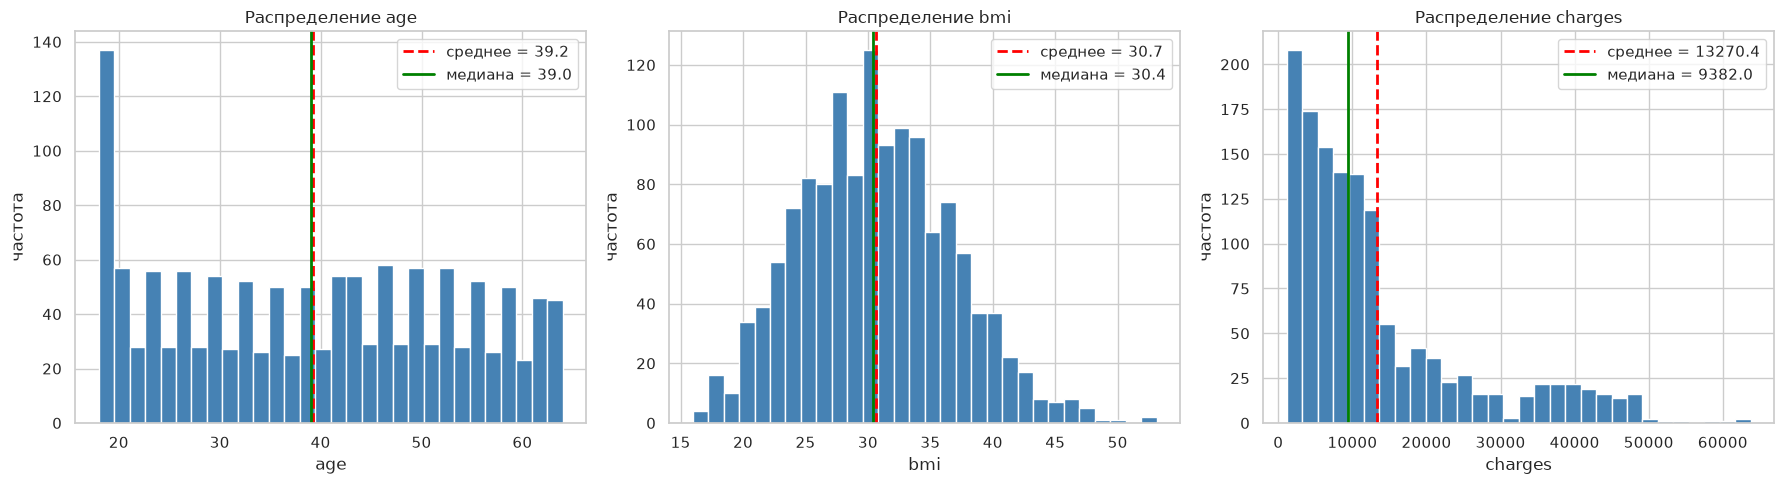

In [7]:
# 3.2 Гистограммы с линиями среднего и медианы
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ["age", "bmi", "charges"]):
    ax.hist(df[col], bins=30, color="steelblue", edgecolor="white")
    mean_v, med_v = df[col].mean(), df[col].median()
    ax.axvline(mean_v, color="red", linestyle="--", linewidth=2, label=f"среднее = {mean_v:.1f}")
    ax.axvline(med_v, color="green", linestyle="-", linewidth=2, label=f"медиана = {med_v:.1f}")
    ax.set_title(f"Распределение {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("частота")
    ax.legend()

plt.tight_layout()
plt.show()

In [8]:
# 3.4 Свойство среднего: M_{x·c} = c·M_x  ( charges_k = charges / 1000 )
df["charges_k"] = df["charges"] / 1000

mean_usd = df["charges"].mean()
mean_k_by_prop = mean_usd * (1 / 1000)   # только свойство, без пересчёта по новым данным
mean_k_by_data = df["charges_k"].mean()  # контрольный пересчёт по данным

print("M_charges (USD):          %.6f" % mean_usd)
print("M_charges_k по свойству:  %.6f   (= M_charges × 1/1000, данные не трогали)" % mean_k_by_prop)
print("M_charges_k по данным:    %.6f   (контрольная проверка)" % mean_k_by_data)
print("Совпадают:", bool(np.isclose(mean_k_by_prop, mean_k_by_data)))

M_charges (USD):          13270.422265
M_charges_k по свойству:  13.270422   (= M_charges × 1/1000, данные не трогали)
M_charges_k по данным:    13.270422   (контрольная проверка)
Совпадают: True


**Вывод (какую меру и почему для каждой переменной):**

- **`age`** (мода 18 лет, медиана 39, среднее 39,2): распределение почти симметричное; «мода 18» — граничный эффект (минимальный допустимый возраст 18 лет, таких 69 человек), а не типичное значение. Среднее и медиана почти совпадают → для слайда берём **среднее ≈ 39 лет** (или медиану — разницы нет).
- **`bmi`** (мода 32,3; медиана 30,4; среднее 30,7): распределение примерно симметричное, слегка скошено вправо из-за хвоста клиентов с высоким BMI. Среднее чуть выше медианы; мода малоинформативна (13 наблюдений). Для слайда — **среднее ≈ 30,7** (медиана 30,4 подойдёт так же).
- **`charges`** (мода 1 639,6; медиана 9 382; среднее 13 270): сильная правосторонняя скошенность — длинный хвост дорогих клиентов. Среднее на 41% выше медианы и тянется за хвостом; мода почти бесполезна (встречается 2 раза). Для слайда про «типичного клиента» — **медиану 9 382 USD**; среднее 13 270 имеет смысл только для бюджета, потому что только оно, умноженное на число клиентов, даёт верную сумму расходов.

**Свойство среднего (3.4):** `charges_k = charges/1000` имеет среднее 13,2704 — в точности `M_charges × (1/1000)` без всякого пересчёта по новым данным: $M_{x \cdot c} = c \cdot M_x$. Проверка по данным совпала.

## Задание 4. Насколько клиенты разные: меры изменчивости

Финансовый отдел утверждает: «Курильщики — это предсказуемый сегмент, они просто дороже». PM сомневается: дороже — да, но **предсказуемее ли**?

**4.1.** Разбейте клиентов на две группы по `smoker`. Для `charges` в каждой группе посчитайте: размах ($R$), дисперсию ($D$, `ddof=1`), стандартное отклонение ($sd$, `ddof=1`). Не забудьте про поправку $n-1$ — объясните в одном предложении, почему она нужна.

**4.2.** Посчитайте те же показатели **вручную** по формулам из лекции для группы курильщиков (через цикл или векторно: отклонения от среднего → квадраты → сумма → деление на $n-1$ → корень) и убедитесь, что результат совпадает с `np.var` / `np.std`.

**4.3.** Свойство дисперсии. В следующем году все выплаты вырастут на фиксированную величину 500 USD (индексация). Как изменятся $D$ и $sd$ для `charges`? А если выплаты вырастут на 10% (умножение на 1.1)? Ответьте сначала **по свойствам**, затем проверьте кодом.

**4.4.** Ответьте PM: какой сегмент более однородный по выплатам — курильщики или некурящие? Что это значит для планирования бюджета?

In [9]:
# 4.1 Размах, дисперсия и sd для charges по группам smoker
smoker_stats = df.groupby("smoker")["charges"].agg(n="count", mean="mean", min="min", max="max")
smoker_stats["R"] = smoker_stats["max"] - smoker_stats["min"]
smoker_stats["D (ddof=1)"] = df.groupby("smoker")["charges"].var(ddof=1)
smoker_stats["sd (ddof=1)"] = df.groupby("smoker")["charges"].std(ddof=1)
smoker_stats["CV = sd/mean, %"] = 100 * smoker_stats["sd (ddof=1)"] / smoker_stats["mean"]
smoker_stats.drop(columns=["min", "max"]).round(2)

,n,mean,R,D (ddof=1),sd (ddof=1),"CV = sd/mean, %"
smoker,,,,,,
no,1064,8434.27,35788.73,3.592542e+07,5993.78,71.06
yes,274,32050.23,50940.97,1.332073e+08,11541.55,36.01


In [10]:
# 4.2 Ручной расчёт D и sd для курильщиков — по шагам, как в лекции
x = df.loc[df["smoker"] == "yes", "charges"].to_numpy()
n = len(x)
mean_x = x.mean()

deviations = x - mean_x          # 1. отклонения от среднего
sq = deviations ** 2             # 2. квадраты отклонений
s = sq.sum()                     # 3. сумма квадратов
d_manual = s / (n - 1)           # 4. делим на n-1
sd_manual = math.sqrt(d_manual)  # 5. корень

print(f"n = {n}, среднее = {mean_x:.2f}")
print(f"Сумма квадратов отклонений: {s:.2f}")
print(f"D  вручную = {d_manual:.4f}   vs np.var(ddof=1)  = {np.var(x, ddof=1):.4f}")
print(f"sd вручную = {sd_manual:.4f}  vs np.std(ddof=1) = {np.std(x, ddof=1):.4f}")
print("Совпадают с numpy:",
      bool(np.isclose(d_manual, np.var(x, ddof=1)) and np.isclose(sd_manual, np.std(x, ddof=1))))

n = 274, среднее = 32050.23
Сумма квадратов отклонений: 36365595959.33
D  вручную = 133207311.2063   vs np.var(ddof=1)  = 133207311.2063
sd вручную = 11541.5472  vs np.std(ddof=1) = 11541.5472
Совпадают с numpy: True


In [11]:
# 4.3 Свойства дисперсии: сдвиг на +500 USD и умножение на 1.1
d0 = df["charges"].var(ddof=1)
sd0 = df["charges"].std(ddof=1)

print("ПО СВОЙСТВАМ:")
print("  прибавка константы (+500): D и sd НЕ изменятся")
print("  умножение на 1.1:          D умножится на 1.1² = 1.21, sd — на 1.1")
print()
print("ПРОВЕРКА КОДОМ:")
print("исходные:            D = %15.2f | sd = %10.2f" % (d0, sd0))
print("после +500:          D = %15.2f | sd = %10.2f" % (np.var(df.charges + 500, ddof=1), np.std(df.charges + 500, ddof=1)))
print("после ×1.1:          D = %15.2f | sd = %10.2f" % (np.var(df.charges * 1.1, ddof=1), np.std(df.charges * 1.1, ddof=1)))
print("ожидание теории:     D = %15.2f | sd = %10.2f  (= D×1.21 и sd×1.1)" % (d0 * 1.21, sd0 * 1.1))

ПО СВОЙСТВАМ:
  прибавка константы (+500): D и sd НЕ изменятся
  умножение на 1.1:          D умножится на 1.1² = 1.21, sd — на 1.1

ПРОВЕРКА КОДОМ:
исходные:            D =    146652372.15 | sd =   12110.01
после +500:          D =    146652372.15 | sd =   12110.01
после ×1.1:          D =    177449370.30 | sd =   13321.01
ожидание теории:     D =    177449370.30 | sd =   13321.01  (= D×1.21 и sd×1.1)


**Вывод:**

Поправка $n-1$ нужна, потому что мы оцениваем дисперсию ГС по выборке: среднее подгоняется под те же самые данные и «съедает» одну степень свободы, поэтому делим на $n-1$, чтобы оценка не занижалась.

| Показатель | Курильщики (n=274) | Некурящие (n=1 064) |
|---|---|---|
| R | 50 941 | 35 789 |
| D (ddof=1) | 133 207 311 | 35 925 420 |
| sd (ddof=1) | 11 541,5 | 5 993,8 |
| среднее | 32 050 | 8 434 |
| CV = sd/среднее | 36,0% | 71,1% |

Ручной расчёт для курильщиков совпал с `np.var`/`np.std` до 4-го знака. Свойства подтвердились кодом: при +500 USD дисперсия и sd **не изменились вовсе** (сдвиг на константу разброс не меняет), при ×1.1 дисперсия выросла ровно в $1.1^2 = 1{,}21$ раза, а sd — в 1,1 раза.

**Ответ PM:** финансовый отдел прав лишь наполовину. Курильщики действительно «просто дороже» — в 3,8 раза по среднему (32 050 против 8 434 USD). Но по абсолютному разбросу (sd = 11 542 USD) они вариативнее, и «предсказуемый сегмент» — только относительно своей средней: коэффициент вариации у курильщиков 36%, у некурящих 71%. Для бюджета: на каждого курильщика закладываем ≈ 32 000 USD с относительно узким коридором; портфель некурящих дешевле, но «шумит» сильнее относительно своей средней — именно там прячутся неожиданно дорогие случаи.

## Задание 5. Аномально дорогие клиенты: квартили, IQR, box plot

PM: «Есть ощущение, что несколько клиентов «съедают» весь бюджет. Сколько их на самом деле и кто они?»

**5.1.** Для `charges` посчитайте $Q1$, $Q2$ (медиану), $Q3$ и $IQR$ (`np.percentile` или `df.charges.quantile`).

**5.2.** По алгоритму из лекции вычислите границы выбросов: $Q1 - 1.5 \cdot IQR$ и $Q3 + 1.5 \cdot IQR$. Посчитайте, **сколько клиентов** попадают в выбросы и **какую долю** от всех выплат компании они составляют.

**5.3.** Постройте box plot `charges` по группам `smoker` (`sns.boxplot(x="smoker", y="charges", data=df)`), а затем — по `region`. Опишите, что видно.

**5.4.** Посмотрите на «выбросы» из п. 5.2: какая среди них доля курильщиков? Какой у них средний `bmi`? Сравните с базой в целом.

**5.5.** Ответьте PM: это действительно аномалии (ошибки данных, которые надо удалить) или это **закономерный сегмент**? Что вы рекомендуете: удалять их из анализа, анализировать отдельно или оставить как есть? Обоснуйте.

In [12]:
# 5.1-5.2 Квартили, IQR, границы выбросов, сколько клиентов и какая доля выплат
q1 = df["charges"].quantile(0.25)
q2 = df["charges"].quantile(0.50)
q3 = df["charges"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df["charges"] < lower) | (df["charges"] > upper)].copy()

print("Q1 = %8.2f | Q2 (медиана) = %8.2f | Q3 = %8.2f" % (q1, q2, q3))
print("IQR = %.2f" % iqr)
print("Границы выбросов: [%.2f ; %.2f]" % (lower, upper))
print()
print("Клиентов-выбросов: %d из %d (%.1f%% базы)" % (len(outliers), len(df), 100 * len(outliers) / len(df)))
print("Их суммарные выплаты: %.0f USD — это %.1f%% всех выплат компании" % (
    outliers.charges.sum(), 100 * outliers.charges.sum() / df.charges.sum()))

Q1 =  4740.29 | Q2 (медиана) =  9382.03 | Q3 = 16639.91
IQR = 11899.63
Границы выбросов: [-13109.15 ; 34489.35]

Клиентов-выбросов: 139 из 1338 (10.4% базы)
Их суммарные выплаты: 5852449 USD — это 33.0% всех выплат компании


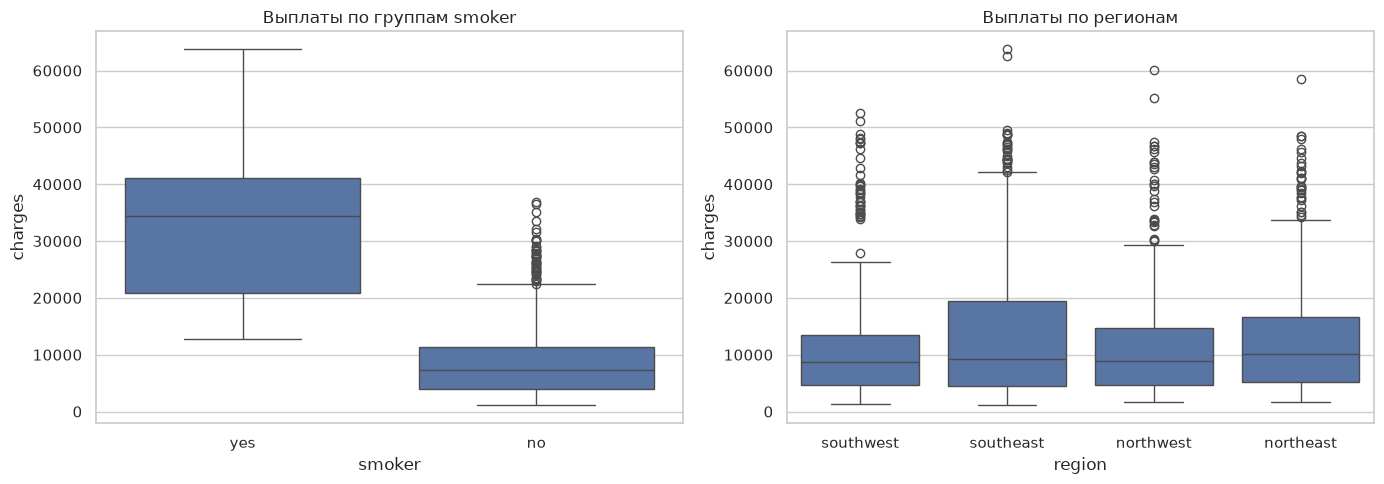

In [13]:
# 5.3 Box plot charges по smoker и по region
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x="smoker", y="charges", data=df, ax=axes[0])
axes[0].set_title("Выплаты по группам smoker")

sns.boxplot(x="region", y="charges", data=df, ax=axes[1])
axes[1].set_title("Выплаты по регионам")

plt.tight_layout()
plt.show()

In [14]:
# 5.4 Портрет клиентов-выбросов
print("Доля курильщиков среди выбросов: %.1f%% (в базе в целом: %.1f%%)" % (
    100 * (outliers.smoker == "yes").mean(), 100 * (df.smoker == "yes").mean()))
print("Средний bmi среди выбросов: %.2f (в базе в целом: %.2f)" % (outliers.bmi.mean(), df.bmi.mean()))
print("Средний возраст: %.1f (в базе %.1f) | среднее число детей: %.2f (в базе %.2f)" % (
    outliers.age.mean(), df.age.mean(), outliers.children.mean(), df.children.mean()))
print("Доля выплат курильщиков, которые приходятся на этих клиентов: %.1f%%" % (
    100 * outliers.loc[outliers.smoker == "yes", "charges"].sum() / df.loc[df.smoker == "yes", "charges"].sum()))
print()
print("Региональное распределение выбросов (доли):")
print(outliers.region.value_counts(normalize=True).round(3).to_string())

Доля курильщиков среди выбросов: 97.8% (в базе в целом: 20.5%)
Средний bmi среди выбросов: 35.56 (в базе в целом: 30.66)
Средний возраст: 41.1 (в базе 39.2) | среднее число детей: 1.19 (в базе 1.09)
Доля выплат курильщиков, которые приходятся на этих клиентов: 65.4%

Региональное распределение выбросов (доли):
region
southeast    0.410
southwest    0.245
northeast    0.201
northwest    0.144


**Вывод:**

- Квартили `charges`: Q1 = 4 740, Q2 = 9 382, Q3 = 16 640 USD; IQR = 11 900. Границы выбросов: [−13 109; 34 489] (нижняя уходит в минус, где данных по понятным причинам нет).
- За верхней границей — **139 клиентов (10,4% базы)**, и на них приходится **33,0% всех выплат компании**: каждый десятый клиент «съедает» треть бюджета — ощущение PM подтверждается.
- Box plot: у некурящих медиана ≈ 8 700 USD, ящик до ≈ 12 000, «ус» к ≈ 35 000; у курильщиков медиана ≈ 34 500, и весь их ящик лежит выше верхнего «уса» некурящих — группы почти не пересекаются. По регионам медианы близки (≈ 8–12 тыс.), но у `southeast` заметно больше дорогих точек и выше «ус» — регион визуально дороже.
- Портрет «выброса»: **97,8% — курильщики** (в базе их 20,5%), средний BMI **35,6** против 30,7 в базе, средний возраст 41,1 года против 39,2, детей в среднем 1,19 против 1,09. На этих 139 клиентов приходится 65,4% всех выплат курильщиков.

**Ответ PM (аномалии или закономерный сегмент?):** это не ошибки данных, а закономерный сегмент «курильщик с высоким BMI». Подтверждение: выбросы не размазаны случайно, а концентрируются в понятной подгруппе с объяснимыми характеристиками. Удалять их нельзя: среднее по базе упало бы с 13 270 до ≈ 9 928 USD (−25%), и анализ потерял бы главный источник расходов. Рекомендация: **анализировать отдельно** — выделить страту «курильщики с высоким BMI» и тарифицировать её индивидуально; в общих выводах по базе среднее и медиану показывать вместе, чтобы скошенность была видна.

## Задание 6. Нормальное распределение, z-оценки и правило 2–3 сигм

Отдел андеррайтинга хочет ввести **надбавку за высокий BMI**: «клиенты с BMI выше 40 — редкость, их можно оценивать индивидуально». Нужно проверить, насколько это редкость.

**6.1.** Постройте гистограмму `bmi` и наложите на неё кривую плотности нормального распределения с параметрами $\mu = \bar{X}_{bmi}$, $\sigma = sd_{bmi}$ (`stats.norm.pdf`). Похоже ли распределение на нормальное «на глаз»?

**6.2.** Выполните **z-стандартизацию** колонки `bmi` (создайте колонку `bmi_z`). Убедитесь, что новое среднее $\approx 0$, а стандартное отклонение $\approx 1$. Форма гистограммы изменилась?

**6.3.** Клиент с ID = 1317 (последняя строка таблицы, `df.iloc[-1]`) — какова его z-оценка по `bmi`? На сколько стандартных отклонений он отличается от среднего клиента и в какую сторону?

**6.4.** Используя нормальную модель ($\mu$, $\sigma$ из п. 6.1) и `stats.norm.sf` / `.cdf`, посчитайте **теоретическую** долю клиентов с `bmi > 40`. Затем посчитайте **фактическую** долю по данным. Насколько они расходятся?

**6.5.** По правилу 2–3 сигм посчитайте, сколько клиентов должны лежать в интервале $[\mu - 2\sigma; \mu + 2\sigma]$ (ожидается $\approx 95.4\%$), и сравните с фактом.

**6.6.** Ответьте отделу андеррайтинга: справедливо ли утверждение «BMI > 40 — редкость»? Какой порог вы бы предложили, если «редкостью» считать верхние 5% клиентов (подсказка: `stats.norm.isf(0.05, mu, sigma)` и `df.bmi.quantile(0.95)` — сравните оба варианта).

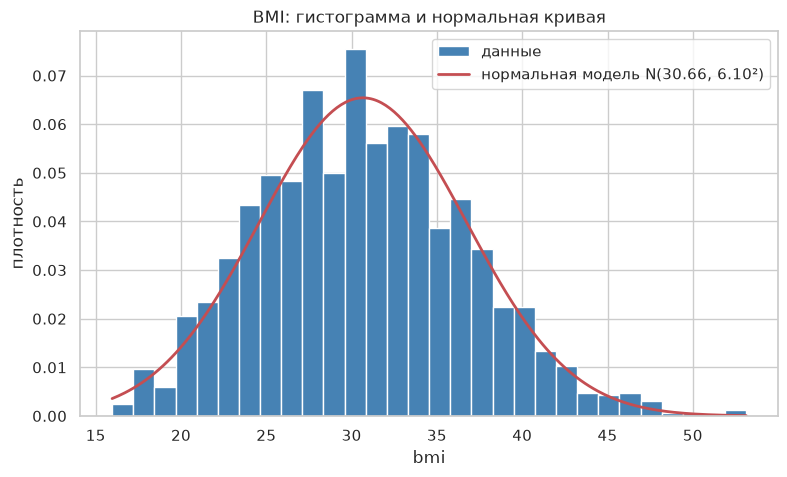

mu = 30.6634, sigma = 6.0982


In [15]:
# 6.1 Гистограмма bmi + нормальная кривая с параметрами mu, sigma выборки
mu_bmi = df["bmi"].mean()
sigma_bmi = df["bmi"].std(ddof=1)

xs = np.linspace(df.bmi.min(), df.bmi.max(), 300)
plt.figure(figsize=(9, 5))
plt.hist(df["bmi"], bins=30, density=True, color="steelblue", edgecolor="white", label="данные")
plt.plot(xs, stats.norm.pdf(xs, mu_bmi, sigma_bmi), "r-", linewidth=2,
         label=f"нормальная модель N({mu_bmi:.2f}, {sigma_bmi:.2f}²)")
plt.title("BMI: гистограмма и нормальная кривая")
plt.xlabel("bmi")
plt.ylabel("плотность")
plt.legend()
plt.show()

print("mu = %.4f, sigma = %.4f" % (mu_bmi, sigma_bmi))

Среднее bmi_z: -0.0000000000 (ожидается 0)
sd bmi_z:      1.0000000000 (ожидается 1)


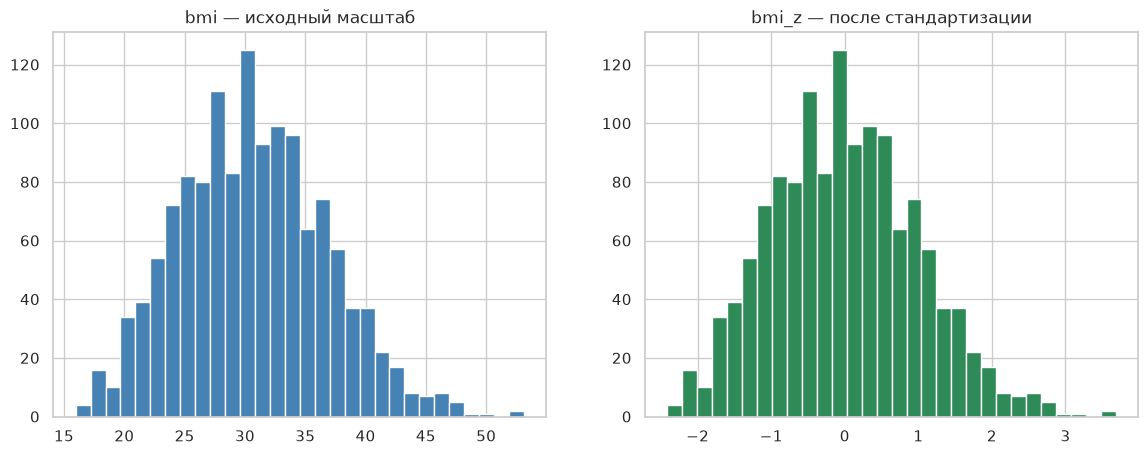

Форма гистограммы не изменилась — изменился только масштаб оси X (линейное преобразование).


In [16]:
# 6.2 z-стандартизация bmi
df["bmi_z"] = (df["bmi"] - df["bmi"].mean()) / df["bmi"].std(ddof=1)

print("Среднее bmi_z: %.10f (ожидается 0)" % df.bmi_z.mean())
print("sd bmi_z:      %.10f (ожидается 1)" % df.bmi_z.std(ddof=1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df["bmi"], bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("bmi — исходный масштаб")
axes[1].hist(df["bmi_z"], bins=30, color="seagreen", edgecolor="white")
axes[1].set_title("bmi_z — после стандартизации")
plt.show()

print("Форма гистограммы не изменилась — изменился только масштаб оси X (линейное преобразование).")

In [17]:
# 6.3 z-оценка последнего клиента (df.iloc[-1])
client = df.iloc[-1]
print(client[["age", "sex", "bmi", "children", "smoker", "region", "charges"]])
print()
print("z-оценка bmi этого клиента: %.3f" % client.bmi_z)
print("Его BMI отличается от среднего клиента на %.2f стандартных отклонения в сторону %s." % (
    abs(client.bmi_z), "ниже среднего" if client.bmi_z < 0 else "выше среднего"))

age                 61
sex             female
bmi              29.07
children             0
smoker             yes
region       northwest
charges     29141.3603
Name: 1337, dtype: object

z-оценка bmi этого клиента: -0.261
Его BMI отличается от среднего клиента на 0.26 стандартных отклонения в сторону ниже среднего.


In [18]:
# 6.4 Теоретическая vs фактическая доля bmi > 40
mu_bmi = df.bmi.mean()
sigma_bmi = df.bmi.std(ddof=1)

theor_share = stats.norm.sf(40, mu_bmi, sigma_bmi)   # P(X > 40) по нормальной модели
emp_share = (df.bmi > 40).mean()
print("P(BMI > 40): теория = %.4f (%.2f%%) | факт = %.4f (%.2f%%) | расхождение = %.2f п.п." % (
    theor_share, 100 * theor_share, emp_share, 100 * emp_share, 100 * abs(theor_share - emp_share)))

# 6.5 Правило 2 сигм
lo, hi = mu_bmi - 2 * sigma_bmi, mu_bmi + 2 * sigma_bmi
inside = (df.bmi >= lo) & (df.bmi <= hi)
print("\nИнтервал [mu-2sd; mu+2sd] = [%.2f ; %.2f]" % (lo, hi))
print("По нормальной модели ожидается 95.45%%, фактически: %.2f%% (n = %d)" % (100 * inside.mean(), inside.sum()))

# 6.6 Порог «верхние 5%»
print("\nПорог верхних 5%% клиентов: по нормальной модели = %.2f | эмпирический квантиль 95%% = %.2f" % (
    stats.norm.isf(0.05, mu_bmi, sigma_bmi), df.bmi.quantile(0.95)))

P(BMI > 40): теория = 0.0629 (6.29%) | факт = 0.0680 (6.80%) | расхождение = 0.51 п.п.

Интервал [mu-2sd; mu+2sd] = [18.47 ; 42.86]
По нормальной модели ожидается 95.45%, фактически: 95.74% (n = 1281)

Порог верхних 5% клиентов: по нормальной модели = 40.69 | эмпирический квантиль 95% = 41.11


**Вывод:**

- Гистограмма BMI с наложенной кривой N(30,66; 6,10²) выглядит колоколообразной и почти симметричной — «на глаз» нормальная модель подходит хорошо (правый хвост чуть тяжелее, но без критических отличий).
- После z-стандартизации: среднее `bmi_z` = 0,0000000000, sd = 1,0000000000 — ровно как должно быть. Форма гистограммы не изменилась, поменялся только масштаб оси X.
- Последний клиент (`df.iloc[-1]`, BMI 29,07): z = **−0,26**, то есть он на 0,26 стандартного отклонения **ниже** среднего клиента — совершенно обычный клиент по BMI.
- P(BMI > 40): теоретическая доля 6,29%, фактическая 6,80% (91 клиент) — расхождение всего 0,5 п.п.; нормальная модель здесь работает.
- Правило 2σ: в интервал [18,47; 42,86] попадают **95,74%** клиентов против теоретических 95,45% — отличное согласие.

**Ответ отделу андеррайтинга:** «BMI > 40 — редкость» — спорная формулировка: это каждый 15-й клиент (6,8%). Если «редкостью» считать верхние 5%, порог по нормальной модели равен **40,7**, по эмпирическому квантилю — **41,1**: оба близки к 40, но чуть строже. Предложение: индивидуально оценивать клиентов с BMI ≳ 41 (верхние 5%), а интервал BMI 30–41 — это не редкость, а заметная часть базы (среднее 30,7!): для неё нужна плавная надбавка, а не индивидуальный разбор.

## Задание 7. Центральная предельная теорема на наших данных

Распределение `charges` (задание 3) явно не нормальное. PM спрашивает: «Тогда как вы вообще собираетесь доверять среднему по выборке?» Ответ на это — ЦПТ. Покажите её на практике.

Снова считаем таблицу из 1 338 клиентов **генеральной совокупностью**.

**7.1.** Извлеките из ГС **1000 выборок** по $n = 50$ клиентов каждая (с возвращением, `df.charges.sample(n=50, replace=True)` в цикле) и для каждой посчитайте среднее `charges`. Постройте гистограмму 1000 выборочных средних.

**7.2.** Сравните:
- среднее ГС и среднее выборочных средних;
- стандартное отклонение выборочных средних (это и есть эмпирическая $se$) и теоретическую $se = \dfrac{sd_{ГС}}{\sqrt{n}}$.

**7.3.** Повторите п. 7.1 для $n = 10$ и $n = 200$. Постройте три гистограммы рядом (одинаковая ось X). Как меняется форма и ширина распределения выборочных средних?

**7.4.** Ответьте PM в 2–3 предложениях: почему мы можем использовать среднее выборки и доверительные интервалы, даже если сами выплаты распределены сильно асимметрично? От чего зависит точность?

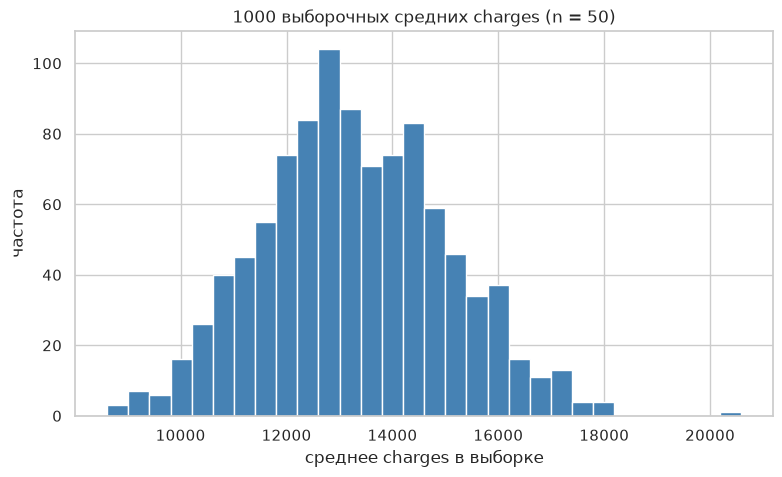

In [19]:
# 7.1 1000 выборок по 50 клиентов (с возвращением) и гистограмма их средних
np.random.seed(42)  # фиксируем генератор, чтобы эксперимент воспроизводился

n_samples = 1000
sample_size = 50
sample_means = [df.charges.sample(n=sample_size, replace=True).mean() for _ in range(n_samples)]

plt.figure(figsize=(9, 5))
plt.hist(sample_means, bins=30, color="steelblue", edgecolor="white")
plt.title("1000 выборочных средних charges (n = 50)")
plt.xlabel("среднее charges в выборке")
plt.ylabel("частота")
plt.show()

In [20]:
# 7.2 Среднее ГС vs среднее средних; эмпирическая vs теоретическая se
emp_se = np.std(sample_means, ddof=1)
theor_se = df.charges.std(ddof=1) / math.sqrt(sample_size)

print("Среднее ГС:              %10.2f" % df.charges.mean())
print("Среднее из 1000 средних: %10.2f  (разница %.2f)" % (np.mean(sample_means), np.mean(sample_means) - df.charges.mean()))
print("Эмпирическая se:         %10.2f" % emp_se)
print("Теоретическая se = sd/√n:%10.2f  (sd_ГС = %.2f, n = %d)" % (theor_se, df.charges.std(ddof=1), sample_size))

Среднее ГС:                13270.42
Среднее из 1000 средних:   13295.66  (разница 25.24)
Эмпирическая se:            1746.02
Теоретическая se = sd/√n:   1712.61  (sd_ГС = 12110.01, n = 50)


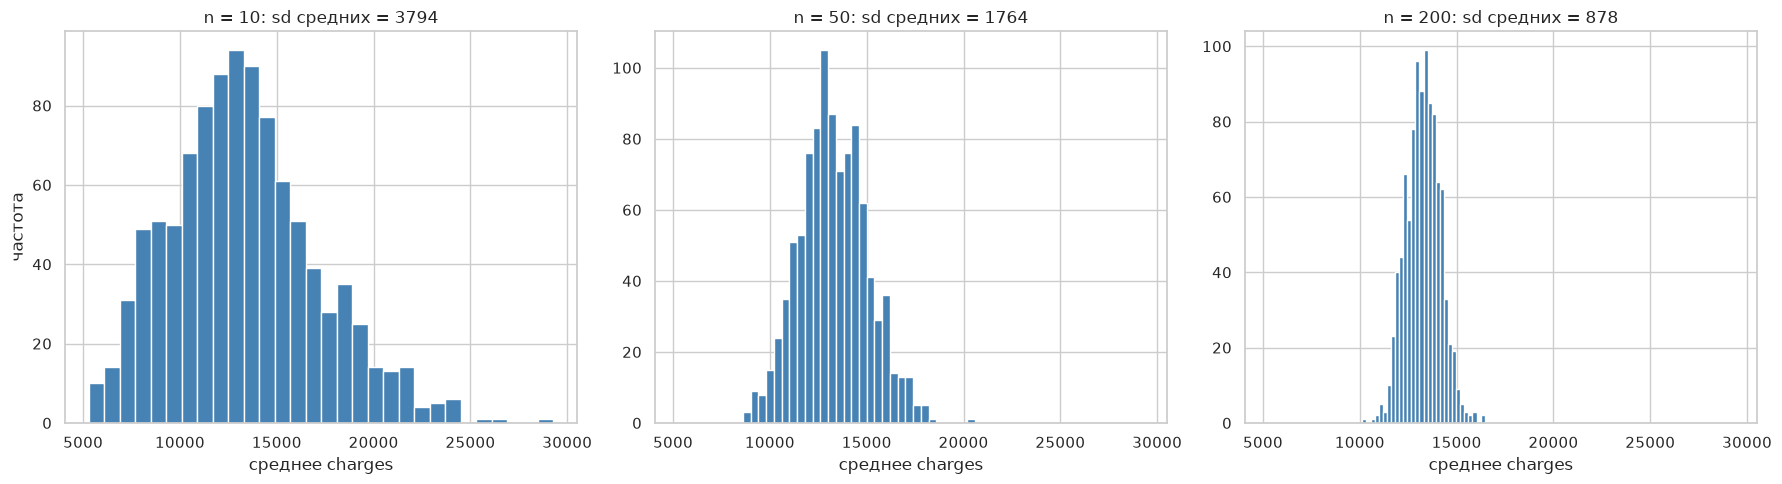

sd_ГС charges = 12110 → теоретические se: n=10 → 3830 | n=50 → 1713 | n=200 → 856


In [21]:
# 7.3 Три размера выборки: n = 10, 50, 200
np.random.seed(42)
means_by_n = {n: [df.charges.sample(n=n, replace=True).mean() for _ in range(1000)]
              for n in [10, 50, 200]}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)
for ax, n in zip(axes, [10, 50, 200]):
    ax.hist(means_by_n[n], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(f"n = {n}: sd средних = %.0f" % np.std(means_by_n[n], ddof=1))
    ax.set_xlabel("среднее charges")
axes[0].set_ylabel("частота")
plt.tight_layout()
plt.show()

print("sd_ГС charges = %.0f → теоретические se: n=10 → %.0f | n=50 → %.0f | n=200 → %.0f" % (
    df.charges.std(ddof=1),
    df.charges.std(ddof=1) / math.sqrt(10),
    df.charges.std(ddof=1) / math.sqrt(50),
    df.charges.std(ddof=1) / math.sqrt(200)))

**Вывод:**

- Гистограмма 1000 выборочных средних (n=50) — почти идеальный колокол вокруг среднего ГС, хотя сами выплаты распределены сильно асимметрично (задание 3). ЦПТ видна на наших данных.
- Среднее 1000 средних = 13 296 USD против среднего ГС 13 270 (разница 0,2%); эмпирическая se = 1 746 USD почти совпала с теоретической se = sd_ГС/√50 = 1 713 USD.
- При росте n распределение средних становится уже и ещё более «нормальным»: sd средних = 3 794 (n=10) → 1 764 (n=50) → 878 (n=200) USD, что совпадает с теоретическими 3 830 / 1 713 / 857: ширина падает как 1/√n.

**Ответ PM:** мы можем доверять среднему выборки и доверительным интервалам, даже когда сами выплаты скошены, потому что по центральной предельной теореме при n ≥ 30 распределение выборочного среднего стремится к нормальному вокруг истинного среднего — форма распределения самих данных на это почти не влияет. Точность оценки зависит от размера выборки (как 1/√n) и от разброса данных (sd): удвоить точность — значит вчетверо увеличить выборку.

## Задание 8. Доверительные интервалы для бюджета

Финансовый отдел планирует резерв на выплаты. Им нужна не одна цифра, а **диапазон**, в котором с высокой уверенностью лежит средняя выплата на клиента.

**8.1.** Возьмите одну случайную выборку из $n = 100$ клиентов (`random_state=1`). Посчитайте $\bar{X}$, $sd$, $se = sd / \sqrt{n}$ для `charges`.

**8.2.** Постройте **95%** и **99%** доверительные интервалы для среднего `charges`. Коэффициенты 1.96 и 2.58 получите через `stats.norm.isf`, как в лекции, а не «из головы».

**8.3.** Проверьте: попадает ли **истинное** среднее ГС (по всем 1 338 клиентам) в ваши интервалы?

**8.4.** Финансовый отдел готов оплатить сбор данных ещё по 300 клиентам (итого $n = 400$). Не пересчитывая ничего по данным, только через формулу $se$, скажите: во сколько раз сузится 95% ДИ? Затем проверьте на реальной выборке из 400 клиентов.

**8.5.** Постройте 95% ДИ для среднего `charges` **отдельно для курильщиков и некурящих** (по всей базе). Пересекаются ли интервалы? Что это говорит PM ещё до всяких формальных тестов?

**8.6.** Напишите одну фразу для финансового отдела в формате: «С уверенностью 95% средняя выплата на клиента лежит в диапазоне от … до … USD», и объясните в одном предложении, что именно означает «95%» (вспомните вопрос из лекции про правильную интерпретацию ДИ).

In [22]:
# 8.1 Одна случайная выборка n = 100
s100 = df.charges.sample(n=100, random_state=1)
x_bar = s100.mean()
sd100 = s100.std(ddof=1)
n100 = len(s100)
se100 = sd100 / math.sqrt(n100)

print("n = %d | X_ = %.2f | sd = %.2f | se = %.2f" % (n100, x_bar, sd100, se100))

n = 100 | X_ = 14859.44 | sd = 12770.68 | se = 1277.07


In [23]:
# 8.2 95% и 99% доверительные интервалы; 8.3 проверка попадания среднего ГС
z95 = stats.norm.isf(0.025)  # двусторонний уровень 5%: α/2 = 0.025 в каждом хвосте
z99 = stats.norm.isf(0.005)  # двусторонний уровень 1%

ci95 = (x_bar - z95 * se100, x_bar + z95 * se100)
ci99 = (x_bar - z99 * se100, x_bar + z99 * se100)

print("z(95%%) = %.4f → 95%% ДИ: [%.2f ; %.2f]" % (z95, *ci95))
print("z(99%%) = %.4f → 99%% ДИ: [%.2f ; %.2f]" % (z99, *ci99))

mu_gs = df.charges.mean()
print()
print("Истинное среднее ГС: %.2f" % mu_gs)
print("Попадает в 95%% ДИ: %s | в 99%% ДИ: %s" % (ci95[0] <= mu_gs <= ci95[1], ci99[0] <= mu_gs <= ci99[1]))

z(95%) = 1.9600 → 95% ДИ: [12356.44 ; 17362.45]
z(99%) = 2.5758 → 99% ДИ: [11569.93 ; 18148.95]

Истинное среднее ГС: 13270.42
Попадает в 95% ДИ: True | в 99% ДИ: True


In [24]:
# 8.4 Эффект увеличения выборки до n = 400
# Теория (только формула se = sd/√n): ширина ДИ ∝ 1/√n → в √(400/100) = 2 раза
print("ТЕОРИЯ: 95% ДИ сузится ровно в 2 раза")
print()

s400 = df.charges.sample(n=400, random_state=1)
se400 = s400.std(ddof=1) / math.sqrt(400)
ci95_400 = (s400.mean() - z95 * se400, s400.mean() + z95 * se400)

width_100 = ci95[1] - ci95[0]
width_400 = ci95_400[1] - ci95_400[0]
print("ПРАКТИКА (n=400): X_ = %.2f | se = %.2f" % (s400.mean(), se400))
print("95%% ДИ: [%.2f ; %.2f] | ширина = %.2f" % (*ci95_400, width_400))
print("Ширина при n=100 = %.2f → фактическое сужение в %.2f раза" % (width_100, width_100 / width_400))

ТЕОРИЯ: 95% ДИ сузится ровно в 2 раза

ПРАКТИКА (n=400): X_ = 13214.13 | se = 596.51
95% ДИ: [12045.00 ; 14383.26] | ширина = 2338.27
Ширина при n=100 = 5006.01 → фактическое сужение в 2.14 раза


In [25]:
# 8.5 95% ДИ для среднего charges отдельно по курильщикам и некурящим (вся база)
for name, grp in df.groupby("smoker"):
    m = grp.charges.mean()
    se_g = grp.charges.std(ddof=1) / math.sqrt(len(grp))
    lo, hi = m - z95 * se_g, m + z95 * se_g
    label = "курильщики  " if name == "yes" else "некурящие   "
    print("%s n = %4d | среднее = %9.2f | 95%% ДИ: [%.2f ; %.2f]" % (label, len(grp), m, lo, hi))

некурящие    n = 1064 | среднее =   8434.27 | 95% ДИ: [8074.12 ; 8794.41]
курильщики   n =  274 | среднее =  32050.23 | 95% ДИ: [30683.65 ; 33416.82]


**Вывод:**

- Выборка n=100 (random_state=1): X̄ = 14 859, sd = 12 771, se = 1 277 USD.
- 95% ДИ: **[12 356; 17 362]** (z = 1,96 из `stats.norm.isf(0.025)`); 99% ДИ: **[11 570; 18 149]** (z = 2,58). Интервал 99% шире — за большую уверенность приходится платить точностью.
- Истинное среднее ГС 13 270 попало в оба интервала — процедура построения сработала корректно (хотя по закону случая так происходит в 95% и 99% повторений, а не всегда).
- Эффект n=400: только по формуле se = sd/√n — 95% ДИ сужается в √(400/100) = **2 раза**. На реальной выборке n=400 сужение получилось 2,14 раза (случайно чуть сильнее теоретических 2×, потому что sd этой выборки оказалась меньше).
- Курильщики: среднее 32 050, 95% ДИ **[30 684; 33 417]**; некурящие: 8 434, 95% ДИ **[8 074; 8 794]**. Интервалы **не пересекаются** — разница между сегментами системная, а не случайная; это видно ещё до формальных тестов.

**Фраза для финансового отдела (по выборке n=100):** «С уверенностью 95% средняя выплата на клиента лежит в диапазоне от 12 356 до 17 362 USD». Здесь «95%» — это не вероятность того, что истина лежит внутри уже построенного интервала (он либо накрыл её, либо нет), а свойство самой процедуры: если строить такие интервалы снова и снова по новым выборкам, в 95% случаев они будут накрывать истинное среднее.

## Задание 9. Проверка гипотез: что из «общеизвестного» в компании правда?

Это главная часть работы. В компании ходят четыре утверждения; PM хочет по каждому получить чёткий вердикт: **подтверждаем / отклоняем**, с $p$-значением и с доверительным интервалом.

Для каждой гипотезы оформите ответ по единой схеме (как в лекции, раздел «Идея статистического вывода»):

1. Сформулировать $H_0$ и $H_1$ (двусторонняя или односторонняя альтернатива — обосновать).
2. Посчитать $\bar{X}$, $sd$, $n$, $se = sd/\sqrt{n}$.
3. Посчитать $z = \dfrac{\bar{X} - M_0}{se}$.
4. Посчитать $p$-значение (`stats.norm.cdf` / `.sf`; можно использовать функцию `p_value` из лекции — она ниже).
5. Построить 95% ДИ и проверить, попадает ли в него $M_0$ — результаты двух подходов должны согласоваться.
6. Вердикт при $\alpha = 0.05$ и **вывод для бизнеса** одним-двумя предложениями.

---

### Гипотеза A. «Средний курильщик обходится нам в 30 000 USD в год»
Маркетинг использует эту цифру в презентациях уже два года. Проверьте: равна ли средняя выплата по курильщикам $M_0 = 30\,000$ USD? (Альтернатива — двусторонняя: нас интересует любое отклонение.)

### Гипотеза B. «Наша целевая аудитория — клиенты 39 лет»
Продуктовая стратегия построена вокруг «среднего клиента 39 лет». Проверьте: равен ли средний возраст клиентов $M_0 = 39$ годам?

### Гипотеза C. «Северо-восток укладывается в бюджет 12 500 USD на клиента»
Финансы заложили в бюджет региона `northeast` среднюю выплату $M_0 = 12\,500$ USD. Проверьте, есть ли основания считать, что реальная средняя выплата по этому региону отличается от бюджета.

### Гипотеза D. «Юго-восток — проблемный регион, там выплаты выше 13 000 USD»
Руководитель по региону `southeast` просит увеличить бюджет, утверждая, что средняя выплата там **превышает** $M_0 = 13\,000$ USD. Здесь альтернатива **односторонняя** («больше») — объясните, почему это меняет расчёт $p$-значения.

### Гипотеза E (бонус, ваша собственная).
Сформулируйте **своё** утверждение о клиентской базе, которое было бы полезно PM (например, про `bmi`, `children` или другой регион), и проверьте его по той же схеме.

In [26]:
# функция из лекции для расчёта p-значения по z-статистике
def p_value(z_stat, alternative="two-sided"):
    if alternative == "two-sided":
        return 2 * (1 - stats.norm.cdf(np.abs(z_stat)))
    if alternative == "less":
        return stats.norm.cdf(z_stat)
    if alternative == "greater":
        return 1 - stats.norm.cdf(z_stat)


def z_test_mean(sample, m0, alternative="two-sided", conf=0.95):
    """
    Заготовка: верните словарь с n, mean, sd, se, z, p, ci_low, ci_high.
    Заполните тело функции сами — и используйте её для всех гипотез.
    """
    sample = np.asarray(sample, dtype=float)
    n = len(sample)
    mean = sample.mean()
    sd = sample.std(ddof=1)
    se = sd / math.sqrt(n)
    z_stat = (mean - m0) / se
    p = p_value(z_stat, alternative)

    alpha = 1 - conf
    if alternative == "two-sided":
        z_crit = stats.norm.isf(alpha / 2)
        ci_low, ci_high = mean - z_crit * se, mean + z_crit * se
    elif alternative == "less":
        z_crit = stats.norm.isf(alpha)
        ci_low, ci_high = -np.inf, mean + z_crit * se
    else:  # "greater"
        z_crit = stats.norm.isf(alpha)
        ci_low, ci_high = mean - z_crit * se, np.inf

    return {"n": n, "mean": mean, "sd": sd, "se": se,
            "z": z_stat, "p": p, "ci_low": ci_low, "ci_high": ci_high}


def show(res, m0):
    # печать результата по единой схеме из лекции
    print("n = %d | X_ = %.2f | sd = %.2f | se = %.2f" % (res["n"], res["mean"], res["sd"], res["se"]))
    print("z = %.4f | p = %.4g" % (res["z"], res["p"]))
    print("95%% ДИ: [%.2f ; %.2f] | M0 = %g внутри ДИ: %s" % (
        res["ci_low"], res["ci_high"], m0, res["ci_low"] <= m0 <= res["ci_high"]))

### Гипотеза A — «средний курильщик = 30 000 USD»

- $H_0$: средняя годовая выплата по курильщикам $M = 30\,000$ USD
- $H_1$: $M \neq 30\,000$ — **двусторонняя** альтернатива: нас интересует любое отклонение от цифры маркетинга, и вверх, и вниз (занижение для компании не менее опасно, чем завышение).

In [27]:
# ваш код: гипотеза A
res_A = z_test_mean(df.loc[df.smoker == "yes", "charges"], m0=30000)
show(res_A, m0=30000)
res_A

n = 274 | X_ = 32050.23 | sd = 11541.55 | se = 697.25
z = 2.9405 | p = 0.003277
95% ДИ: [30683.65 ; 33416.82] | M0 = 30000 внутри ДИ: False


{'n': 274,
 'mean': np.float64(32050.23183153284),
 'sd': np.float64(11541.547175589121),
 'se': np.float64(697.2503639985891),
 'z': np.float64(2.94045286656457),
 'p': np.float64(0.003277328586437589),
 'ci_low': np.float64(30683.646229888163),
 'ci_high': np.float64(33416.81743317752)}

**Вердикт и вывод для бизнеса:** p = 0,0033 < 0,05 → **отклоняем $H_0$**. Средняя выплата курильщика = 32 050 USD, z = 2,94, 95% ДИ [30 684; 33 417] — значение 30 000 в него не попадает. Цифра маркетинга занижена примерно на 2 050 USD (≈7%): если тарифы и презентации строились на 30 000, компания недозакладывает ~2 тыс. USD резерва на каждого курильщика — презентации и тарифную модель надо пересчитать.

### Гипотеза B — «средний возраст клиента = 39 лет»

- $H_0$: средний возраст клиентов $M = 39$ лет
- $H_1$: $M \neq 39$ — **двусторонняя** альтернатива: возраст и выше, и ниже заявленного делает «портрет среднего клиента» неверным.

In [28]:
# ваш код: гипотеза B
res_B = z_test_mean(df["age"], m0=39)
show(res_B, m0=39)
res_B

n = 1338 | X_ = 39.21 | sd = 14.05 | se = 0.38
z = 0.5390 | p = 0.5899
95% ДИ: [38.45 ; 39.96] | M0 = 39 внутри ДИ: True


{'n': 1338,
 'mean': np.float64(39.20702541106129),
 'sd': np.float64(14.049960379216154),
 'se': np.float64(0.38410241948323204),
 'z': np.float64(0.5389849179805168),
 'p': np.float64(0.5898972613133704),
 'ci_low': np.float64(38.45419850249946),
 'ci_high': np.float64(39.95985231962312)}

**Вердикт и вывод для бизнеса:** p = 0,590 > 0,05 → **оснований отклонять $H_0$ нет**. Средний возраст = 39,2 года, z = 0,54, 95% ДИ [38,45; 39,96] — 39 попадает внутрь. Утверждение «средний клиент — 39 лет» статистически подтверждается: продуктовая стратегия вокруг этого портрета остаётся корректной, пересматривать её из-за возраста не нужно.

### Гипотеза C — «northeast: средняя выплата = 12 500 USD»

- $H_0$: средняя выплата в регионе `northeast` $M = 12\,500$ USD
- $H_1$: $M \neq 12\,500$ — **двусторонняя** альтернатива: бюджет неверен и при завышении, и при занижении — в обоих случаях финансовый план региона строится на неверной цифре.

In [29]:
# ваш код: гипотеза C
res_C = z_test_mean(df.loc[df.region == "northeast", "charges"], m0=12500)
show(res_C, m0=12500)
res_C

n = 324 | X_ = 13406.38 | sd = 11255.80 | se = 625.32
z = 1.4495 | p = 0.1472
95% ДИ: [12180.78 ; 14631.99] | M0 = 12500 внутри ДИ: True


{'n': 324,
 'mean': np.float64(13406.384516385804),
 'sd': np.float64(11255.803065578462),
 'se': np.float64(625.3223925321367),
 'z': np.float64(1.4494675501952745),
 'p': np.float64(0.1472070560997687),
 'ci_low': np.float64(12180.775148296398),
 'ci_high': np.float64(14631.99388447521)}

**Вердикт и вывод для бизнеса:** p = 0,147 > 0,05 → **отклонить $H_0$ нельзя**. Средняя выплата = 13 406 USD, z = 1,45, 95% ДИ [12 181; 14 632] — бюджетные 12 500 внутри интервала, формально бюджет не опровергнут. Но точечная оценка на 906 USD (7%) выше бюджета, а вся верхняя половина ДИ лежит выше 12 500: рекомендую держать небольшой резерв (~8–10%) или запросить уточнённую оценку — риск превышения бюджета заметный.

### Гипотеза D — «southeast: средняя выплата > 13 000 USD»

- $H_0$: средняя выплата в регионе `southeast` $M = 13\,000$ USD
- $H_1$: $M > 13\,000$ — **односторонняя** альтернатива
- Почему односторонняя альтернатива и как это влияет на $p$: руководитель региона заявляет именно о **превышении** и просит увеличить бюджет — интересует только правый хвост. Вся $\alpha = 0{,}05$ отдаётся в одну сторону: $p = P(Z \geq z) = 1 - \Phi(z)$ без умножения на 2, а критическое значение 1,645 вместо 1,96. При той же z-статистике односторонний тест даёт p ровно вдвое меньше двустороннего, поэтому корректно сравнивать результат можно только с критическим значением той же односторонней постановки.

In [30]:
# ваш код: гипотеза D
res_D = z_test_mean(df.loc[df.region == "southeast", "charges"], m0=13000, alternative="greater")
show(res_D, m0=13000)
res_D

n = 364 | X_ = 14735.41 | sd = 13971.10 | se = 732.28
z = 2.3699 | p = 0.008897
95% ДИ: [13530.91 ; inf] | M0 = 13000 внутри ДИ: False


{'n': 364,
 'mean': np.float64(14735.411437609888),
 'sd': np.float64(13971.098588991747),
 'se': np.float64(732.2845401593519),
 'z': np.float64(2.369859450033243),
 'p': np.float64(0.008897424203657356),
 'ci_low': np.float64(13530.910555768287),
 'ci_high': inf}

**Вердикт и вывод для бизнеса:** p = 0,0089 < 0,05 → **отклоняем $H_0$**, утверждение подтверждается. Средняя выплата в `southeast` = 14 735 USD, z = 2,37, односторонний 95% ДИ [13 531; +∞) — 13 000 вне интервала, подходы согласуются. Бюджет региона надо закладывать выше 13 000 USD; точечно — ≈14 700 на клиента (запас к заявленному уровню ≈13%).

### Гипотеза E (бонус) — «средний BMI клиентов превышает 30»

Полезное PM утверждение: по классификации ВОЗ BMI ≥ 30 — ожирение. Если *средний* клиент MedGuard уже в зоне ожирения, это меняет базовый уровень риска для всех тарифов, а не только для отдельной надбавки.

- $H_0$: средний BMI клиентов $M = 30$
- $H_1$: $M > 30$ — **односторонняя** альтернатива: важно именно превышение порога ожирения (симметричное «отличие в любую сторону» практического смысла не имеет).

In [31]:
# ваш код: гипотеза E
res_E = z_test_mean(df["bmi"], m0=30, alternative="greater")
show(res_E, m0=30)
res_E

n = 1338 | X_ = 30.66 | sd = 6.10 | se = 0.17
z = 3.9792 | p = 3.457e-05
95% ДИ: [30.39 ; inf] | M0 = 30 внутри ДИ: False


{'n': 1338,
 'mean': np.float64(30.66339686098655),
 'sd': np.float64(6.098186911679014),
 'se': np.float64(0.1667142315007415),
 'z': np.float64(3.9792455329981697),
 'p': np.float64(3.4567156609655036e-05),
 'ci_low': np.float64(30.389176352638128),
 'ci_high': inf}

**Вердикт и вывод для бизнеса:** p ≈ 3,5·10⁻⁵ < 0,05 → **отклоняем $H_0$**. Средний BMI клиентов = 30,66, z = 3,98, односторонний 95% ДИ [30,39; +∞) — порог 30 вне интервала. Средний клиент MedGuard статистически достоверно находится в зоне ожирения: базовый уровень риска тарифа надо калибровать исходя из этого, а надбавку за BMI имеет смысл начинать фактически от ~30, а не от 40.

### Ошибки I и II рода — вопрос без кода

PM спрашивает: «Если мы отклонили гипотезу A и пересчитаем тарифы для курильщиков, чем мы рискуем, если на самом деле маркетинг был прав?»

Опишите, какая это ошибка (I или II рода), и приведите пример **обратной** ошибки для одной из гипотез B–D: что произойдёт с бизнесом, если мы её совершим.

**Ответ:** Если мы отклонили $H_0$ (сказали «среднее не 30 000»), а на самом деле маркетинг был прав и $M = 30\,000$ — это **ошибка I рода** (отклонили верную нулевую гипотезу). Последствие: тарифы для курильщиков будут пересчитаны по ложной причине — заложим неверную маржу, можем отпугнуть клиентов завышенной ценой или недополучить прибыль.

**Обратная ошибка (II рода)** — не отклонить $H_0$, хотя она ложна. Пример для гипотезы D: если бы мы совершили ошибку II рода, признав среднюю выплату в `southeast` равной 13 000 USD, хотя она реально выше (14 735). Для бизнеса это означало бы недофинансированный бюджет региона: резерва не хватит на фактические выплаты, и разницу компании придётся покрывать из собственных средств либо рисковать невыплатой обязательств.

## Итоговый отчёт для PM

**Данные.** 1 338 клиентов, 7 признаков, пропусков нет. Количественные: `age`, `bmi`, `children`, `charges`; номинативные: `sex`, `smoker`, `region`.

**Портрет клиента.** Типичный клиент — 39 лет, BMI ≈ 30–31, медианная выплата 9 382 USD (средняя 13 270 USD выше из-за хвоста дорогих кейсов — на слайде лучше обе цифры).

**Главный драйвер расходов — курильщики.** 20,5% базы, средняя выплата 32 050 USD против 8 434 у некурящих (95% ДИ не пересекаются). 139 клиентов с выплатами > 34 489 USD (10% базы) — почти все курильщики со средним BMI 35,6 — забирают 33% всех выплат. Это не аномалии данных, а отдельный тарифный сегмент.

**Вердикты по «общеизвестному»:**
| Утверждение | Вердикт | p | Факты |
|---|---|---|---|
| A. Курильщик = 30 000 USD | отклонено | 0,003 | реально 32 050 (ДИ 30 684–33 417) |
| B. Средний клиент 39 лет | подтверждено | 0,590 | 39,2 года (ДИ 38,45–39,96) |
| C. Northeast укладывается в 12 500 | не отклонено | 0,147 | 13 406, бюджет в ДИ, но точечно +7% — держать резерв |
| D. Southeast дороже 13 000 | подтверждено | 0,009 | 14 735, закладывать ≈14 700 |
| E (наш тест). Средний BMI > 30 | подтверждено | ≈3,5·10⁻⁵ | 30,66 — базовый риск калибровать под ожирение |

**Рекомендации.**
1. Тарифы строить по сегментам `smoker` × `region`, а не «в среднем по базе» — средние различаются в разы.
2. Индивидуальная оценка андеррайтинга — для BMI ≳ 41 (верхние 5%); надбавка за риск должна начинаться с BMI ≈ 30.
3. Выводы по выборкам отчитывать доверительными интервалами: n=100 даёт ±2 500 USD, n=400 — вдвое точнее; одна выборка из 100 без интервала — неосновательный риск.
4. «Дорогие» клиенты из задания 5 не удаляются, а выделяются в отдельную страту с индивидуальным тарифом — они закономерны и предсказуемы (курильщики с высоким BMI).